# 02 · Training: the long tail, and teaching a model which mistakes matter

Two questions drive this notebook.

The first is ordinary and hard: how do you train a classifier where one
species has 7,207 photographs and another has two? The answer matters
more for *how you measure* than for how you train, because the obvious
metric hides almost everything interesting.

The second is specific to this project. Cross-entropy treats every
mistake as equally bad. Here they are not. Confusing two harmless
species costs nothing; confusing a toxic species for a harmless one is
the failure the system exists to prevent. The second half is about
building that asymmetry into the objective and measuring whether it
worked.

*Assumes the long tail and bucket definitions from
[`01_the_data_problem`](01_the_data_problem.ipynb). Leads into
[`03_safety_logic`](03_safety_logic.ipynb), which consumes the output.*

## 1. The recipe, and what it can fairly be compared to

The benchmark model deliberately copies the Pl@ntNet-300K paper's setup,
so that a number produced here means roughly what a number there means:

> All models are pre-trained on ImageNet. During training, images are
> resized to 256 and a random crop of size 224 x 224 is extracted.
> During test time, we take the centered crop. The models are optimized
> with SGD with a momentum of 0.9 with the Nesterov acceleration. We use
> a batch size of 32 for all models and a weight decay of 1e-4.
>
> Garcin et al., *Pl@ntNet-300K*, NeurIPS Datasets and Benchmarks 2021.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plant_toxicity_checker import training_log
from plant_toxicity_checker.config import DEFAULT_BACKBONE_RUN, DEFAULT_RUN

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 92}}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

OUTPUTS_DIR = Path("../outputs")
CONFIGS_DIR = Path("../configs")
BENCHMARK, SHIPPED = DEFAULT_BACKBONE_RUN, DEFAULT_RUN
BENCHMARK_LABEL = "ResNet-18 (benchmark)"
SHIPPED_LABEL = "ConvNeXt V2-Tiny (shipped)"
BENCHMARK_COLOR, SHIPPED_COLOR = "#8c8c8c", "#2d5f8a"
ACCENT, WARN = "#c77700", "#b3202c"


def load_json(path):
    return json.loads((OUTPUTS_DIR / path).read_text(encoding="utf-8"))


EVALS = {
    BENCHMARK_LABEL: load_json(f"{BENCHMARK}/eval_test.json"),
    SHIPPED_LABEL: load_json(f"{SHIPPED}/eval_test_epoch30_ema.json"),
}
BREAKDOWN = load_json(f"{SHIPPED}/species_breakdown_test_epoch30.json")
BENCH_BREAKDOWN = load_json(f"{BENCHMARK}/species_breakdown_test.json")
TRAIN_COUNTS = np.array([s["train_count"] for s in BREAKDOWN["species"]],
                        dtype=float)
print(f"test split: {sum(s['n_eval'] for s in BREAKDOWN['species']):,} photos")

test split: 31,106 photos


In [2]:
recipes = {}
for label, name in ((BENCHMARK_LABEL, "plantnet_baseline"),
                    (SHIPPED_LABEL, "plantnet_convnextv2_tiny_toxicity_v2")):
    recipes[label] = json.loads(
        (CONFIGS_DIR / f"{name}.json").read_text(encoding="utf-8"))

KEYS = ["model", "optimizer", "lr", "weight_decay", "batch_size", "epochs",
        "scheduler", "warmup_steps", "grad_accum_steps", "ema_decay",
        "sampler", "toxicity_cost_weight"]
table = pd.DataFrame(
    {label: {key: recipe.get(key, "-") for key in KEYS}
     for label, recipe in recipes.items()}
)
table.loc["scheduler"] = [
    "multistep (x0.1 at 20, 25)" if v == "-" else v
    for v in table.loc["scheduler"]
]
display(table)

,ResNet-18 (benchmark),ConvNeXt V2-Tiny (shipped)
model,resnet18,convnextv2_tiny
optimizer,sgd,adamw
lr,0.01,0.0002
weight_decay,0.0001,0.05
batch_size,32,16
epochs,30,30
scheduler,"multistep (x0.1 at 20, 25)",cosine
warmup_steps,-,500
grad_accum_steps,-,4
ema_decay,-,0.9996


Three caveats on comparability, none of them small.

**Different architecture.** The paper benchmarks 27 architectures and
reports its per-bin table with **ResNet-50**. The benchmark here is
ResNet-18, chosen because it trains in about 35 hours on one GTX 1070
rather than several days. Anyone wanting a broad architecture comparison
on this dataset should read the paper, not this repo.

**Different dataset version.** The paper reports on **v1** (1,081
species); this project uses **v2** (1,000 species). Numbers are close
enough to be suggestive and not close enough to be equal.

**Different goal.** The shipped model drops the paper's recipe entirely:
AdamW, cosine schedule, square-root frequency sampling and a
toxicity-aware term. It is not a benchmark entry. Sections 5 to 7 are
about why each of those changed.

## 2. Why plain top-1 is misleading here

This is the most important measurement idea in the project, and the
paper reaches the same conclusion: it recommends **macro-average top-k**
rather than plain top-k.

Plain top-1 weights every *photograph* equally. From
[`01_the_data_problem`](01_the_data_problem.ipynb): half the training
photographs come from 37 species. So plain top-1 is close to a report on
those 37, and a model can move a great deal on the other 963 without
shifting it.

Macro-average computes accuracy per species, then averages with every
species weighted equally.

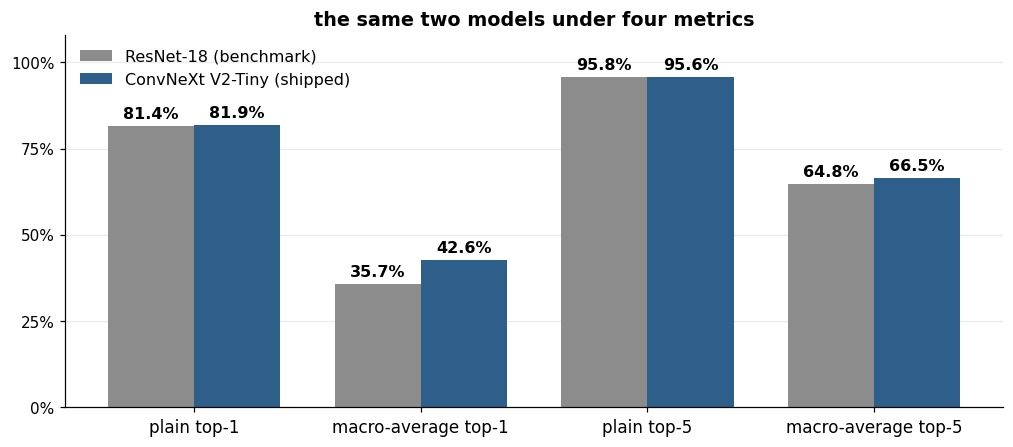

plain top-1            +0.5%
macro-average top-1    +6.8%
plain top-5            -0.1%
macro-average top-5    +1.6%


In [3]:
PAIRS = [("plain top-1", "top_1"), ("macro-average top-1", "macro_top_1"),
         ("plain top-5", "top_5"), ("macro-average top-5", "macro_top_5")]

figure, axis = plt.subplots(figsize=(11, 4.4))
width, positions = 0.38, np.arange(len(PAIRS))
for offset, (label, color) in zip(
        (-width / 2, width / 2),
        ((BENCHMARK_LABEL, BENCHMARK_COLOR), (SHIPPED_LABEL, SHIPPED_COLOR))):
    values = [EVALS[label][key] for _, key in PAIRS]
    bars = axis.bar(positions + offset, values, width, color=color,
                    label=label)
    axis.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=3,
                   fontsize=10.5, fontweight="bold")
axis.set_xticks(positions)
axis.set_xticklabels([label for label, _ in PAIRS], fontsize=11)
axis.set_ylim(0, 1.08)
axis.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axis.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
axis.legend(fontsize=10.5, frameon=False, loc="upper left")
axis.grid(axis="y", alpha=0.25)
axis.set_axisbelow(True)
axis.set_title("the same two models under four metrics", fontsize=12.5,
               fontweight="bold")
plt.show()

for label, key in PAIRS:
    delta = EVALS[SHIPPED_LABEL][key] - EVALS[BENCHMARK_LABEL][key]
    print(f"{label:22s} {delta:+.1%}")

The two metrics disagree about how much changed. Plain top-1 moves by
about half a point; macro-average top-1 moves by about seven. Both are
correct measurements of different populations, and only one of them can
see the long tail.

Everything after this section is read through macro-average. Where plain
top-1 appears it is for continuity with the benchmark, not because it is
the number that matters.

## 3. Accuracy against training-set size

Macro-average says the gain is in rare species. This section says
exactly where.

The first panel uses this project's buckets. The second re-bins into the
paper's bins so its ResNet-50 column can sit alongside, with one
correction that matters: the paper reports **mean bin accuracy**, the
mean of per-species accuracy within a bin, not the pooled per-photograph
rate. Pooling would flatter every model in the rare bins, so the figures
here are computed the paper's way.

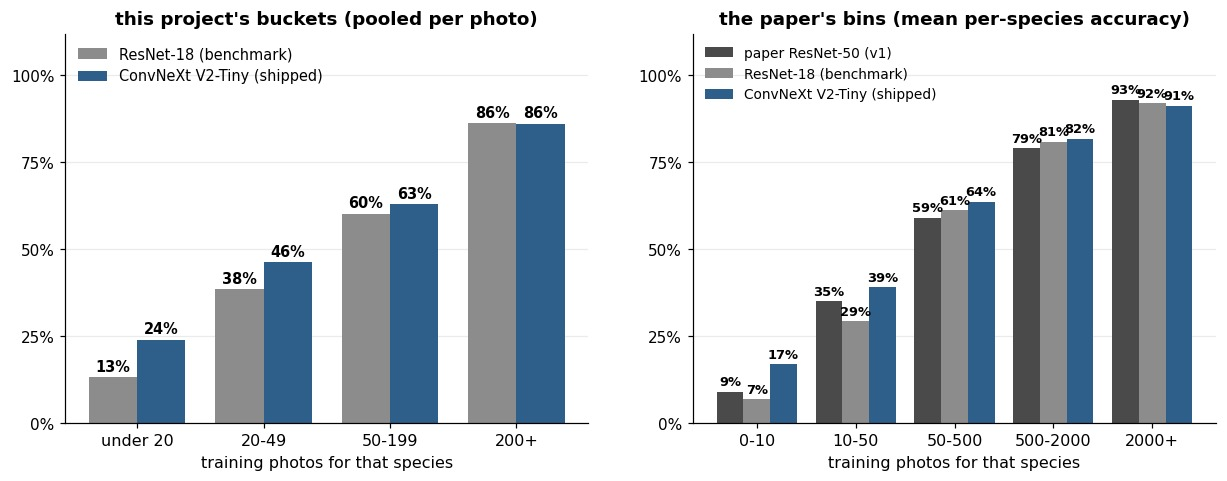

In [4]:
# The paper's Table 1 (ResNet-50, v1 test). Its column is "mean bin
# accuracy" - the mean of PER-SPECIES accuracy inside a bin, not the
# pooled per-photo rate - so ours is computed the same way below.
PAPER_BINS = [(0, 10, 0.09), (10, 50, 0.35), (50, 500, 0.59),
              (500, 2000, 0.79), (2000, np.inf, 0.93)]


def mean_bin_accuracy(breakdown, low, high):
    """Mean of per-species top-1 inside a bin, over species that have
    at least one evaluation photo."""
    values = [s["top1_accuracy"] for s in breakdown["species"]
              if low <= s["train_count"] < high and s["n_eval"] > 0]
    return float(np.mean(values)) if values else np.nan


figure, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

OUR_ORDER = ["<20", "20-49", "50-199", "200+"]
OUR_LABEL = {"<20": "under 20", "20-49": "20-49", "50-199": "50-199",
             "200+": "200+"}
width, positions = 0.38, np.arange(len(OUR_ORDER))
for offset, (breakdown, label, color) in zip(
        (-width / 2, width / 2),
        ((BENCH_BREAKDOWN, BENCHMARK_LABEL, BENCHMARK_COLOR),
         (BREAKDOWN, SHIPPED_LABEL, SHIPPED_COLOR))):
    values = [breakdown["buckets"][b]["top1_accuracy"] for b in OUR_ORDER]
    bars = axes[0].bar(positions + offset, values, width, color=color,
                       label=label)
    axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in values], padding=2,
                      fontsize=9.5, fontweight="bold")
axes[0].set_xticks(positions)
axes[0].set_xticklabels([OUR_LABEL[b] for b in OUR_ORDER], fontsize=10.5)
axes[0].legend(fontsize=9.5, frameon=False, loc="upper left")
axes[0].set_title("this project's buckets (pooled per photo)",
                  fontsize=12, fontweight="bold")

labels = [f"{int(lo)}-{'inf' if np.isinf(hi) else int(hi)}"
          for lo, hi, _ in PAPER_BINS]
labels[-1] = "2000+"
positions = np.arange(len(PAPER_BINS))
width = 0.27
series = [
    ("paper ResNet-50 (v1)", [p for _, _, p in PAPER_BINS], "#4a4a4a"),
    (BENCHMARK_LABEL, [mean_bin_accuracy(BENCH_BREAKDOWN, lo, hi)
                       for lo, hi, _ in PAPER_BINS], BENCHMARK_COLOR),
    (SHIPPED_LABEL, [mean_bin_accuracy(BREAKDOWN, lo, hi)
                     for lo, hi, _ in PAPER_BINS], SHIPPED_COLOR),
]
for index, (label, values, color) in enumerate(series):
    bars = axes[1].bar(positions + (index - 1) * width, values, width,
                       color=color, label=label)
    axes[1].bar_label(bars, labels=[f"{v:.0%}" for v in values], padding=2,
                      fontsize=8.5, fontweight="bold")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(labels, fontsize=10.5)
axes[1].legend(fontsize=9, frameon=False, loc="upper left")
axes[1].set_title("the paper's bins (mean per-species accuracy)",
                  fontsize=12, fontweight="bold")

for axis in axes:
    axis.set_ylim(0, 1.12)
    axis.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    axis.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
    axis.set_xlabel("training photos for that species", fontsize=10.5)
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
plt.show()

The shape matches the paper's across the whole range, which is the main
thing worth knowing: nothing here is anomalous, and the long-tail
weakness is a property of the dataset rather than of this training run.

The gains from the shipped model sit almost entirely in the rare bins.
The best-represented bin barely moves, which is what plain top-1 was
reporting on in section 2.

Direct comparison with the ResNet-50 column is still not apples to
apples (v1 against v2, and a larger backbone), so read it as a sanity
check on shape rather than a ranking.

## 4. Handling the imbalance: square-root frequency sampling

The benchmark model does nothing about the long tail: it draws images
uniformly, so a species with 7,207 photographs contributes 3,604 times
as much as one with two.

The shipped model draws each image with weight `1 / sqrt(n)`, where `n`
is its species' photo count, following Mahajan et al. (2018). A species
then appears in proportion to `sqrt(n)` rather than `n`. An epoch draws
as many images as the dataset holds, so this redistributes a fixed
budget rather than adding to it.

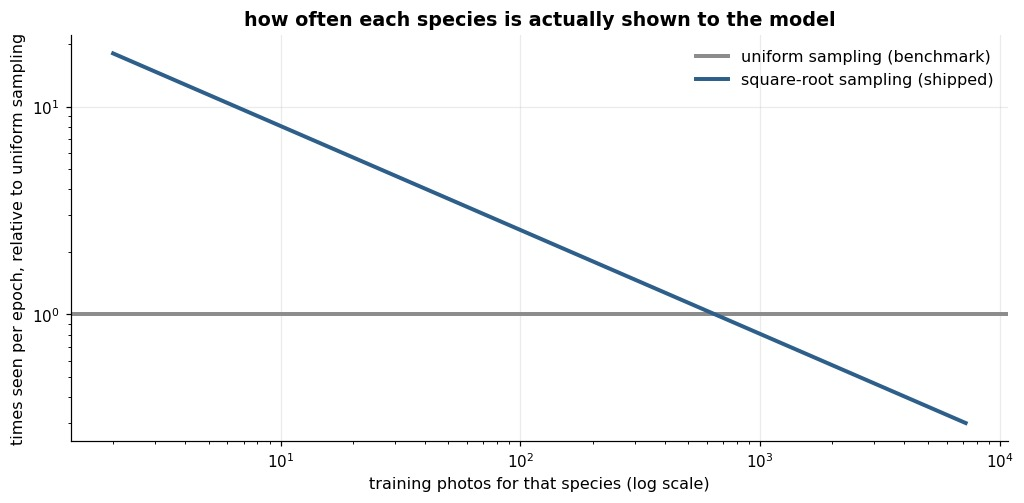

imbalance ratio  uniform 3,604:1   square-root 60:1
rarest species seen 18x more often; commonest seen at 30% of its uniform rate


In [5]:
counts = TRAIN_COUNTS
total = counts.sum()
sqrt_probability = np.sqrt(counts) / np.sqrt(counts).sum()
exposure = sqrt_probability * total / counts   # multiples of natural rate

order = np.argsort(counts)
figure, axis = plt.subplots(figsize=(11, 4.8))
axis.axhline(1.0, color=BENCHMARK_COLOR, linewidth=2.6,
             label="uniform sampling (benchmark)")
axis.plot(counts[order], exposure[order], linewidth=2.6,
          color=SHIPPED_COLOR, label="square-root sampling (shipped)")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("training photos for that species (log scale)",
                fontsize=10.5)
axis.set_ylabel("times seen per epoch, relative to uniform sampling",
                fontsize=10.5)
axis.set_title("how often each species is actually shown to the model",
               fontsize=12.5, fontweight="bold")
axis.legend(fontsize=10.5, frameon=False, loc="upper right")
axis.grid(alpha=0.25)
axis.set_axisbelow(True)
plt.show()

common = counts >= 2000
print(f"imbalance ratio  uniform {counts.max() / counts.min():,.0f}:1   "
      f"square-root {np.sqrt(counts.max() / counts.min()):.0f}:1")
print(f"rarest species seen {exposure[counts.argmin()]:.0f}x more often; "
      f"commonest seen at {exposure[counts.argmax()]:.0%} of its "
      f"uniform rate")

The imbalance ratio compresses from **3,604:1 to 60:1**, and because the
budget is fixed, the boost to rare species is paid for by the common
ones: the commonest species is seen at **30% of its natural rate**.

Other long-tail methods exist, including loss reweighting such as
Class-Balanced loss and Balanced Softmax, and decoupled classifier
retraining. Several were tried here and none earned a place in the
shipped model; the runs are left in `outputs/` for anyone who wants
them. Section 7 names the one change still worth making.

## 5. The toxicity-aware objective

The core contribution. Cross-entropy treats confusing *Hypericum
perforatum* for another *Hypericum* exactly like confusing it for a
harmless *Calendula*. Only the second one can get a cat poisoned.

The cost term adds a penalty when the predicted species falls on the
opposite side of the toxic/non-toxic boundary from the true one,
weighted by `toxicity_cost_weight`. The model still predicts a species
and never a toxicity verdict: the term changes which species-confusions
are expensive, nothing more.

**Which signal it may use is deliberately broader than the verdict
path.** From [`01_the_data_problem`](01_the_data_problem.ipynb): the
cost term draws on all 274 species with any toxicity signal, exact or
genus-inferred, verified or not, because a wrong weight on a loss term
costs accuracy rather than safety. The verdict path still uses only the
34 hand-verified exact entries. Species with no signal are excluded from
the term rather than guessed at.

The metric it targets is the **toxic/non-toxic confusion rate**: how
often the top-1 prediction lands on the other side of the boundary, among
species where both sides are known. Top-1 and top-5 cannot see this
distinction at all.

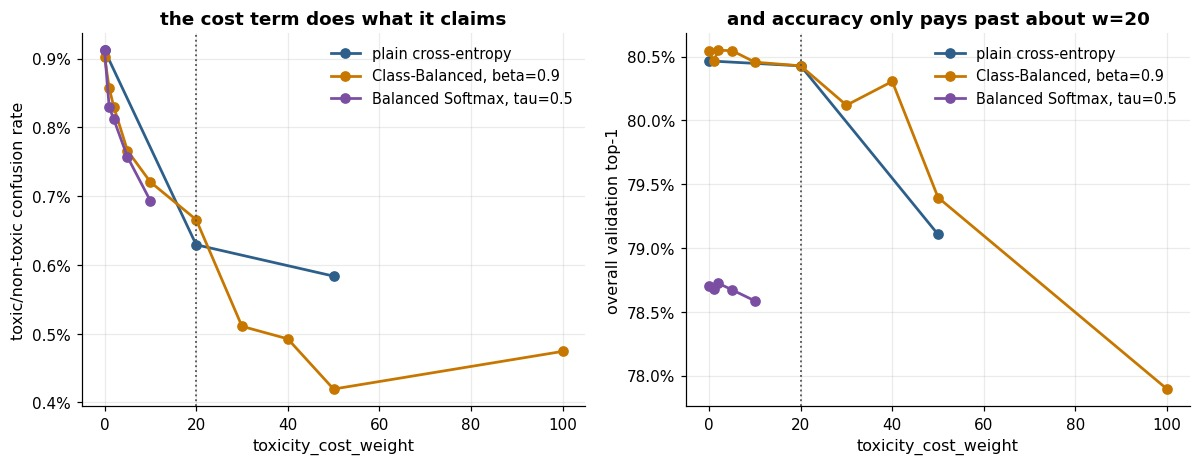

test split, shipped model against the benchmark:
   ResNet-18 (benchmark)        confusion 0.86%   top-1 81.4%   macro top-1 35.7%
   ConvNeXt V2-Tiny (shipped)   confusion 0.27%   top-1 81.9%   macro top-1 42.6%
   relative reduction: 68%


In [6]:
# The proxy models the weight was swept on: the Phase 1 backbone frozen
# with only a linear head retrained, which costs minutes rather than the
# 35 hours a full run takes.
runs = []
for directory in sorted(OUTPUTS_DIR.glob("decoupled_*")):
    evaluation = directory / "eval_val.json"
    if not evaluation.exists():
        continue
    e = json.loads(evaluation.read_text(encoding="utf-8"))
    runs.append({"run": directory.name, "top1": e["top_1"],
                 "confusion": e["toxic_confusion"]["confusion_rate"]})
runs = pd.DataFrame(runs)

# One line per BASE configuration. Several bases share a family (two
# different Class-Balanced betas, for instance), and joining those into
# one series would draw a zigzag between unrelated runs.
def weight_of(name):
    return 0.0 if "_toxicity_w" not in name else float(
        name.split("_toxicity_w", 1)[1].split("_")[0])


def base_of(name):
    return name.split("_toxicity_w", 1)[0].removesuffix("_toxicity")


sweep = runs[~runs["run"].str.endswith("_seed1")].copy()
sweep["weight"] = sweep["run"].map(weight_of)
sweep["base"] = sweep["run"].map(base_of)
BASES = {
    "decoupled_ce": ("plain cross-entropy", "#2d5f8a"),
    "decoupled_cb_loss_beta0.9": ("Class-Balanced, beta=0.9", "#c77700"),
    "decoupled_balanced_softmax_tau0.5": ("Balanced Softmax, tau=0.5",
                                          "#7b4ea3"),
}
sweep = sweep[sweep["base"].isin(BASES)].sort_values("weight")

figure, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for base, (label, color) in BASES.items():
    group = sweep[sweep["base"] == base]
    for axis, column in zip(axes, ("confusion", "top1")):
        axis.plot(group["weight"], group[column], "o-", markersize=6,
                  color=color, label=label, linewidth=1.8)
axes[0].set_ylabel("toxic/non-toxic confusion rate", fontsize=10.5)
axes[0].set_title("the cost term does what it claims", fontsize=12,
                  fontweight="bold")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
axes[1].set_ylabel("overall validation top-1", fontsize=10.5)
axes[1].set_title("and accuracy only pays past about w=20", fontsize=12,
                  fontweight="bold")
# the spread here is under 3 points, so whole percents would repeat
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
for axis in axes:
    axis.axvline(20, color="#555555", linestyle=":", linewidth=1.2)
    axis.set_xlabel("toxicity_cost_weight", fontsize=10.5)
    axis.legend(fontsize=9.5, frameon=False)
    axis.grid(alpha=0.25)
    axis.set_axisbelow(True)
plt.show()

print("test split, shipped model against the benchmark:")
for label in (BENCHMARK_LABEL, SHIPPED_LABEL):
    e = EVALS[label]
    print(f"   {label:28s} confusion "
          f"{e['toxic_confusion']['confusion_rate']:.2%}   "
          f"top-1 {e['top_1']:.1%}   macro top-1 {e['macro_top_1']:.1%}")
benchmark_rate = EVALS[BENCHMARK_LABEL]["toxic_confusion"]["confusion_rate"]
shipped_rate = EVALS[SHIPPED_LABEL]["toxic_confusion"]["confusion_rate"]
print(f"   relative reduction: "
      f"{(benchmark_rate - shipped_rate) / benchmark_rate:.0%}")

**The weight was not tuned on the shipped model.** Training the full
ConvNeXt run takes about 35 hours, so sweeping a hyperparameter on it is
not practical. Instead the sweep below was run on cheaper proxy models:
the Phase 1 backbone frozen, with only a linear head retrained on cached
features, which costs minutes per variant. `toxicity_cost_weight=20`
was chosen there and carried over to the shipped run unchanged.

The sweep shows the trade turning sharp. Up to about `w=20` the
confusion rate falls at no measurable cost in accuracy. Past it,
accuracy starts paying.

On the test split the shipped model cuts the confusion rate from
**0.86% to 0.27%**, a 68% relative reduction, while plain top-1 moves by
+0.5 points and macro-average top-1 by +6.8. The error the project
exists to prevent got three times rarer and the species accuracy did not
suffer for it.

One caveat on attribution: the shipped run changed the backbone, the
optimiser, the schedule, the sampler and the loss at once, so the 0.27%
cannot be credited to the cost term alone. The decoupled sweep is the
cleaner evidence, since there only the loss changed: 0.91% to 0.63% on
validation with the backbone held fixed.

## 6. Making training stable

ConvNeXt with AdamW on this hardware does not train smoothly by
default. Batch size is capped at 16 by 8 GB of VRAM, which makes each
gradient estimate noisy, and a noisy gradient with a constant learning
rate never settles. The shipped run uses three mechanisms to deal with
that.

**Gradient accumulation**, 4 steps. Gradients from 4 micro-batches are
summed before the optimiser steps, giving an effective batch of 64 at
batch-16 memory cost. Gradient noise falls roughly with the square root
of batch size.

**Cosine schedule** with 500 warmup steps. The learning rate rises from
near zero, then decays smoothly to near zero by the final epoch, so the
run finishes in a settled state rather than wherever the last noisy step
left it. Warmup matters because AdamW's moment estimates are unreliable
for the first few hundred steps, and a full-rate update on top of them
was enough to collapse an earlier attempt at a higher learning rate.

**EMA of the weights**, decay 0.9996. A shadow copy of the weights is
kept as an exponential moving average, so the evaluated model is an
average over the last few thousand steps rather than one arbitrary
point. This is what is actually evaluated and shipped.

The decay deserves a note, because it is a *per-optimiser-step*
quantity. At batch 16 an epoch is about 15,242 micro-batches, but
gradient accumulation means the optimiser steps only about 3,810 times.
A decay calibrated against micro-batches averages over four times as
much history as intended, which is exactly the bug that produced an EMA
reading 7.4% accuracy. The fix is 0.9999^4 = 0.9996.

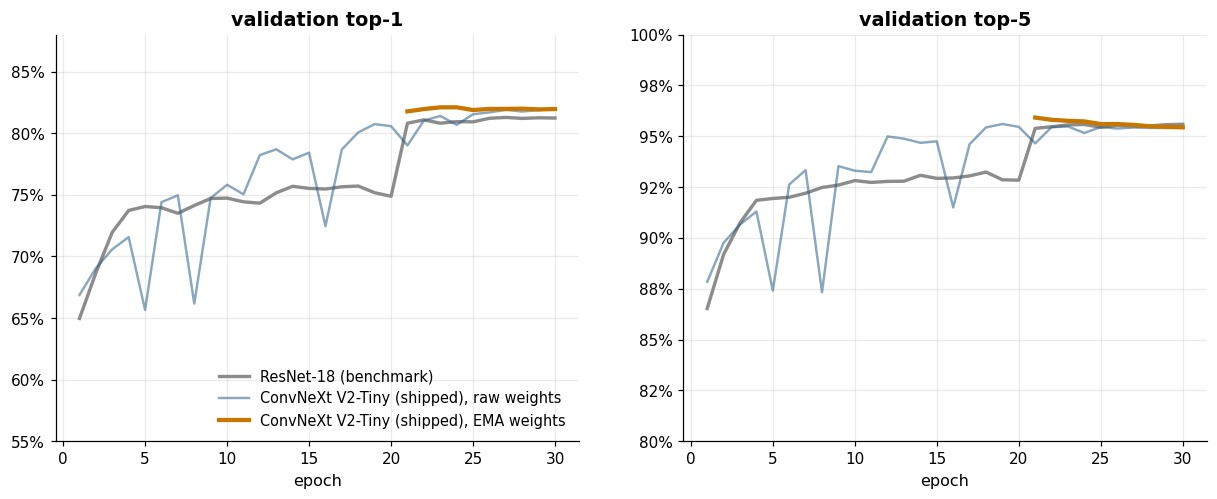

ResNet-18 (benchmark)        epoch 30: top-1 81.2%  top-5 95.6%
ConvNeXt V2-Tiny (shipped)   epoch 30: top-1 82.0%  top-5 95.4%
  of which EMA weights       epoch 30: top-1 82.0%  top-5 95.4%


In [7]:
def epochs_for(run_name):
    """Per-epoch validation accuracy for a run. Part of the shipped
    run's log was lost to a truncating resume, so any missing epoch is
    reconstructed from its per-epoch species breakdown, which holds the
    same numbers."""
    parsed = {e["epoch"]: dict(e)
              for e in training_log.fetch_all_epochs(run_name)}
    pattern = "species_breakdown_val_epoch*.json"
    for path in (OUTPUTS_DIR / run_name).glob(pattern):
        epoch = int(path.stem.rsplit("epoch", 1)[1])
        if epoch in parsed and parsed[epoch].get("val_top1") is not None:
            continue
        b = json.loads(path.read_text(encoding="utf-8"))
        n = sum(s["n_eval"] for s in b["species"])
        parsed[epoch] = {
            "epoch": epoch,
            "val_top1": sum(s["top1_accuracy"] * s["n_eval"]
                            for s in b["species"]) / n,
            "val_top5": sum(s["top5_accuracy"] * s["n_eval"]
                            for s in b["species"]) / n,
            "ema_val_top1": parsed.get(epoch, {}).get("ema_val_top1"),
            "ema_val_top5": parsed.get(epoch, {}).get("ema_val_top5"),
        }
    return [parsed[k] for k in sorted(parsed)]


benchmark_run = epochs_for(BENCHMARK)
shipped_run = epochs_for(SHIPPED)

figure, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for axis, (title, raw_key, ema_key) in zip(
        axes,
        (("validation top-1", "val_top1", "ema_val_top1"),
         ("validation top-5", "val_top5", "ema_val_top5"))):
    axis.plot([e["epoch"] for e in benchmark_run],
              [e[raw_key] for e in benchmark_run], "-", linewidth=2.2,
              color=BENCHMARK_COLOR, label=BENCHMARK_LABEL)
    axis.plot([e["epoch"] for e in shipped_run],
              [e[raw_key] for e in shipped_run], "-", linewidth=1.6,
              color=SHIPPED_COLOR, alpha=0.55,
              label=f"{SHIPPED_LABEL}, raw weights")
    ema = [(e["epoch"], e[ema_key]) for e in shipped_run if e.get(ema_key)]
    axis.plot([e for e, _ in ema], [v for _, v in ema], "-", linewidth=2.8,
              color=ACCENT, label=f"{SHIPPED_LABEL}, EMA weights")
    axis.set_title(title, fontsize=12.5, fontweight="bold")
    axis.set_xlabel("epoch", fontsize=10.5)
    axis.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    axis.grid(alpha=0.25)
    axis.set_axisbelow(True)
axes[0].set_ylim(0.55, 0.88)
axes[1].set_ylim(0.80, 1.0)
axes[0].legend(fontsize=9.5, frameon=False, loc="lower right")
plt.show()

for label, epochs in ((BENCHMARK_LABEL, benchmark_run),
                      (SHIPPED_LABEL, shipped_run)):
    last = epochs[-1]
    print(f"{label:28s} epoch {last['epoch']}: "
          f"top-1 {last['val_top1']:.1%}  top-5 {last['val_top5']:.1%}")
ema_last = [e for e in shipped_run if e.get("ema_val_top1")][-1]
print(f"{'  of which EMA weights':28s} epoch {ema_last['epoch']}: "
      f"top-1 {ema_last['ema_val_top1']:.1%}  "
      f"top-5 {ema_last['ema_val_top5']:.1%}")

Both models reach a similar place by different routes. The benchmark
climbs smoothly, with the step at epoch 20 coming from its multi-step
schedule dropping the learning rate tenfold. The shipped run swings far
more from epoch to epoch, which is the small batch and the resampler
repeating a 2-photograph species 18 times an epoch.

The EMA curve is the one that matters, and it is flat: the final epoch
is a safe choice precisely because averaging has removed the swings the
raw curve still shows. It is drawn only from epoch 21 because this
run's earlier log was lost to a truncating resume. The raw curve for
those epochs was recovered from the per-epoch species breakdowns, which
do not record EMA.

Top-5 is near-saturated for both, which is part of why section 2
argued for macro-average: at 95% there is very little left for a metric
to report.

## 7. What is still open

**Inference-side options.** Test-time augmentation and ensembling were
never tried. Both are cheap, neither requires retraining, and both
usually buy a point or so.

**A thresholded resampler.** Square-root sampling suppresses common
species to 30% of their natural rate because the epoch budget is fixed.
LVIS repeat-factor sampling, `r = max(1, sqrt(t / f))`, repeats rare
classes without ever suppressing common ones, at the cost of a slightly
longer epoch. It has not been run here and is the most promising
untested change in the project.

**Checkpoint selection on the right metric.** The final epoch ships.
Two earlier epochs score about 1.1 points higher on test macro-average,
which suggests selecting on validation macro-average rather than taking
the last epoch is worth a look.

**More training would buy very little.** Validation accuracy was still
climbing in the early twenties, so this is a claim about the tail, not
the whole run: over the last five epochs training loss fell by about a
third while validation top-1 moved 0.3 points. The returns are
diminishing fast and the widening gap is memorisation. A longer run is
not where the next real gain is.

The honest summary is that the species classifier is close to done for
this hardware and this dataset, and that
[`01_the_data_problem`](01_the_data_problem.ipynb) already identified
where the real constraint sits: toxicity-table coverage, not model
accuracy.